In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import re

from out import PaperData, papers_list

# Configure style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 7)

In [2]:
# Initialize collector
papers = PaperData()

for paper in papers_list:
    papers.add_entry(paper)

# Convert to DataFrame when ready for analysis
research_df = papers.to_dataframe()

In [3]:
print("DataFrame created with {} entries.".format(len(research_df)))

DataFrame created with 47 entries.


In [4]:
def split_data_rows(df, split_string):
    # Create a new DataFrame to store the split data
    is_split = False
    new_rows = []
    for _, row in df.iterrows():
        new_rows_tmp = []
        for col in df.columns:
            if (not row[col] == None) and (split_string in row[col]):
                parts = row[col].split(split_string)
                for index, part in enumerate(parts):
                    if not is_split:
                        new_row = row.copy()
                        new_row[col] = part.strip()
                        new_rows_tmp.append(new_row)
                    else:
                        #print(row)
                        new_rows_tmp[index][col] = part.strip()
                is_split = True
        new_rows.extend(new_rows_tmp)
        if not is_split:
            new_rows.append(row)
        is_split = False

    new_df = pd.DataFrame(new_rows)
    return new_df

def pre_process_data(df):
    """
    Pre-process the DataFrame to prepare it for analysis.
    """    
    # Go though all columns and remove all strings within parentheses
    for col in df.columns:
        if df[col].dtype == 'object':
            # Handle newlines within parentheses using DOTALL mode ((?s))
            df[col] = df[col].str.replace(r'(?s)\([^)]*\)', '', regex=True).str.strip()
    
    # Look for all ------- and split data row in two rows, copying the common part
    df = split_data_rows(df, '-------')
    df = split_data_rows(df, '---1---')
    df = split_data_rows(df, '---2---')

    # Replace commas in numeric strings
    for col in df.columns:
        if df[col].dtype == 'object':
            # Clean up special characters that might cause parsing issues
            df[col] = df[col].str.replace(',', '')
            df[col] = df[col].str.replace('*', '')
            df[col] = df[col].str.replace('$', '')
            df[col] = df[col].str.replace('approx', '')
            df[col] = df[col].str.strip()

    return df

## Basic graphs

In [5]:
# Plot the number of papers per year
fig1 = px.histogram(research_df, x='Year', title='Number of Papers per Year')
fig1.show()

In [6]:
# Create a copy of the dataframe for visualization
network_types_df = research_df.copy()
network_types_df['Network Type/s'] = network_types_df['Network Type/s'].str.replace('\n---1---\n', ' or ')

# Plot the distribution of network types with improved visualization
fig2 = px.pie(network_types_df, names='Network Type/s', 
              title='Distribution of NN Types per Paper',
              hole=0,
              color_discrete_sequence=px.colors.qualitative.Bold)

# Add border around segments
fig2.update_traces(marker=dict(line=dict(color='#000000', width=2)))

# Improve layout
fig2.update_layout(legend_title_text='Network Type',
                  margin=dict(t=50, b=50, l=50, r=50))

fig2.show()

In [7]:
# Replace None values with "Unknown" for better visualization
research_df['Accelerator Architecture'] = research_df['Accelerator Architecture'].fillna("Unknown")

# Plot the distribution of accelerator architectures with improved title
fig3 = px.pie(research_df, names='Accelerator Architecture', 
              title='Distribution Accelerator Architectures per Paper',
              hole=0,
              color_discrete_sequence=px.colors.qualitative.Bold)

# Add border around segments and show percentage values
fig3.update_traces(marker=dict(line=dict(color='#000000', width=2)))

# Improve layout
fig3.update_layout(legend_title_text='Architecture Type',
                  margin=dict(t=50, b=50, l=50, r=50))

fig3.show()

In [8]:
# Pre-process the DataFrame for analysis
df_for_analysis = pre_process_data(research_df)
# Display the first few rows of the cleaned DataFrame
print("DataFrame created with {} entries.".format(len(df_for_analysis)))

DataFrame created with 81 entries.


## Deterministic analysis

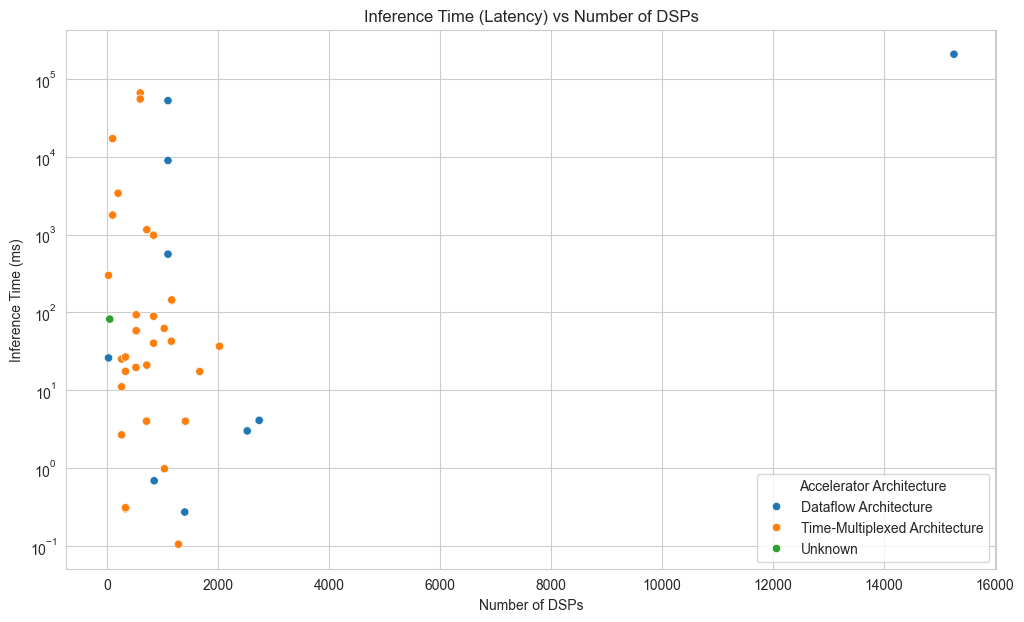

In [9]:
# Function to extract DSPs and convert latency to milliseconds
def extract_dsp_latency(row):
    dsp_match = re.search(r'(\d+)\s*DSP', row['FPGA Resources Consumption'])
    latency_match = re.search(r'(\d+(\.\d+)?)\s*(ms|$mu s$|s)', row['Inference Time (Latency)'])
    
    if dsp_match and latency_match:
        dsp = int(dsp_match.group(1))
        latency_value = float(latency_match.group(1))
        latency_unit = latency_match.group(3)
        
        if latency_unit == '$mu s$':
            latency = latency_value / 1000  # Convert microseconds to milliseconds
        elif latency_unit == 's':
            latency = latency_value * 1000  # Convert seconds to milliseconds
        else:
            latency = latency_value  # Already in milliseconds
        
        return pd.Series([dsp, latency])
    return pd.Series([None, None])

# Apply the function to extract DSPs and latency
temp_df = df_for_analysis[['FPGA Resources Consumption', 'Inference Time (Latency)', 'Accelerator Architecture']].dropna()
temp_df[['DSPs', 'Latency (ms)']] = temp_df.apply(extract_dsp_latency, axis=1)

# Drop rows with missing values
temp_df = temp_df.dropna(subset=['DSPs', 'Latency (ms)'])

# Plot the data with a logarithmic scale on the y-axis and different colors for 'Accelerator Architecture'
plt.figure()
sns.scatterplot(data=temp_df, x='DSPs', y='Latency (ms)', hue='Accelerator Architecture')
plt.yscale('log')
plt.title('Inference Time (Latency) vs Number of DSPs')
plt.xlabel('Number of DSPs')
plt.ylabel('Inference Time (ms)')
plt.legend(title='Accelerator Architecture', bbox_to_anchor=(1, 0), loc='lower right')
plt.show()


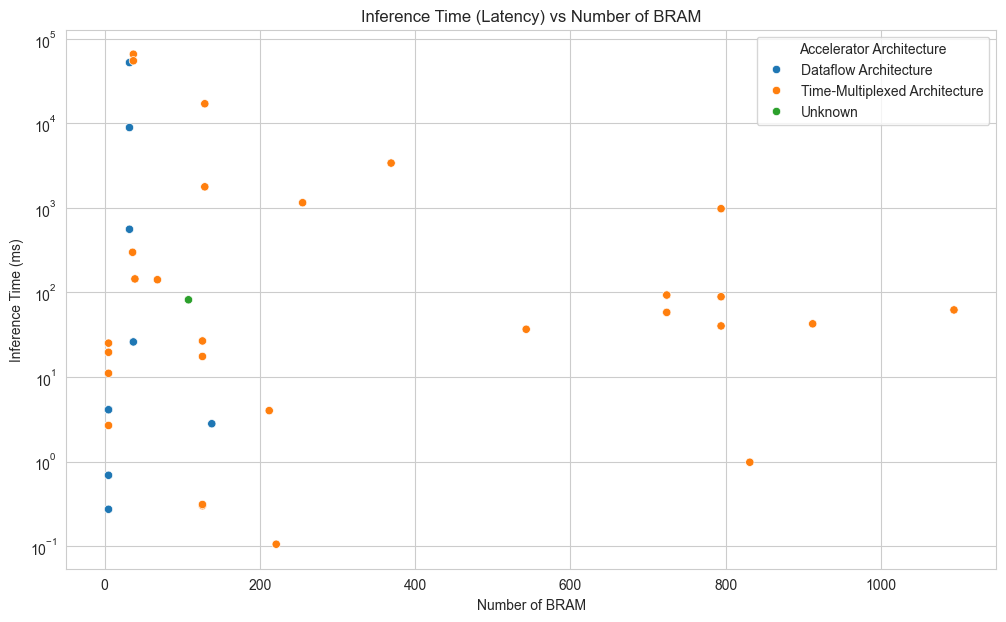

In [10]:
# Function to extract BRAM and convert latency to milliseconds
def extract_bram_latency(row):
    bram_match = re.search(r'(\d+)\s*BRAM', row['FPGA Resources Consumption'])
    latency_match = re.search(r'(\d+(\.\d+)?)\s*(ms|$mu s$|s)', row['Inference Time (Latency)'])
    
    if bram_match and latency_match:
        bram = int(bram_match.group(1))
        latency_value = float(latency_match.group(1))
        latency_unit = latency_match.group(3)
        
        if latency_unit == '$mu s$':
            latency = latency_value / 1000  # Convert microseconds to milliseconds
        elif latency_unit == 's':
            latency = latency_value * 1000  # Convert seconds to milliseconds
        else:
            latency = latency_value  # Already in milliseconds
        
        return pd.Series([bram, latency])
    return pd.Series([None, None])

# Apply the function to extract BRAM and latency
temp_df = df_for_analysis[['FPGA Resources Consumption', 'Inference Time (Latency)', 'Accelerator Architecture']].dropna()
temp_df[['BRAM', 'Latency (ms)']] = temp_df.apply(extract_bram_latency, axis=1)

# Drop rows with missing values
temp_df = temp_df.dropna(subset=['BRAM', 'Latency (ms)'])

# Plot the data with a logarithmic scale on the y-axis and different colors for 'Accelerator Architecture'
plt.figure()
sns.scatterplot(data=temp_df, x='BRAM', y='Latency (ms)', hue='Accelerator Architecture')
plt.yscale('log')
plt.title('Inference Time (Latency) vs Number of BRAM')
plt.xlabel('Number of BRAM')
plt.ylabel('Inference Time (ms)')
plt.legend(title='Accelerator Architecture', bbox_to_anchor=(1, 1), loc='upper right')
plt.show()

## Energy related graphs

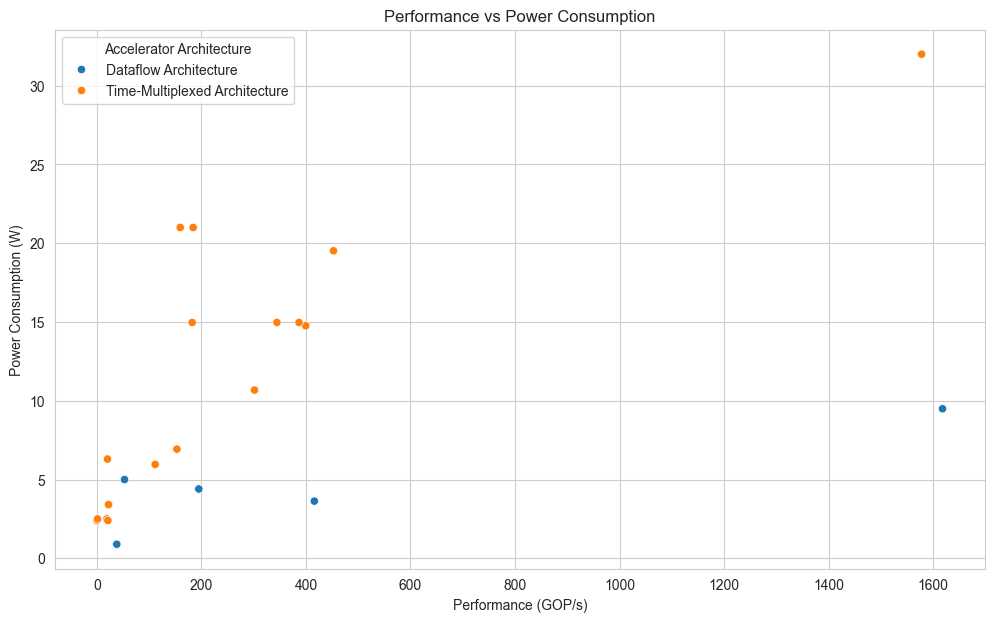

In [13]:
# Apply the function to extract BRAM and latency
temp_df = df_for_analysis[['Performance (GOP/s)', 'Power Consumption', 'Accelerator Architecture']].dropna()

# Extract numeric values from 'Performance (GOP/s)' and convert to float
temp_df['Performance (OPS/s)'] = temp_df['Performance (GOP/s)'].str.extract(r'(\d+(\.\d+)?)')[0].astype(float)
# Extract numeric values from 'Power Consumption' and convert to float
temp_df['Power Consumption'] = temp_df['Power Consumption'].str.extract(r'(\d+(\.\d+)?)')[0].astype(float)

# Plot the data with a logarithmic scale on the y-axis and different colors for 'Accelerator Architecture'
plt.figure()
sns.scatterplot(data=temp_df, x='Performance (OPS/s)', y='Power Consumption', hue='Accelerator Architecture')
#plt.yscale('log')
plt.title('Performance vs Power Consumption')
plt.xlabel('Performance (GOP/s)')
plt.ylabel('Power Consumption (W)')
plt.legend(title='Accelerator Architecture', bbox_to_anchor=(0, 1), loc='upper left')
plt.show()